# Lucerne Drum Patterns Meta Audiobox Aesthetics Evaluation

**Meta Audiobox Aesthetics Evaluation of the Lucerne Drum Patterns Stimulus Set from the Lucerne Groove Research Library (Senn et al., 2023).**

This notebook serves as the analytical companion and supplementary material for the manuscript: *"Human vs. AI: Do Meta Audiobox Aesthetic Scores Align with Human Perceived Music Complexity? A Study of Popular Drum Patterns."* It takes the standardized stimulus set of forty popular music drum patterns—the "Lucerne Drum Patterns" (LDP) belonging to the Lucerne Groove Research Library, from the work of Senn et al. (2023)—and evaluates them using the Meta Audiobox Aesthetics Evaluation (AES) model (Tjandra et al., 2025). It computes scores across the four AES dimensions (*Production Quality*, *Production Complexity*, *Content Enjoyment*, and *Content Usefulness*), tests format sensitivity between native MP3 files and PCM WAV conversions via paired *t*-tests with Bonferroni correction, evaluates rank correlations and LOWESS trajectories on the WAV renditions against human *Perceived Complexity* (Bradley–Terry $\beta$), and fits random forest models to examine predictive relationships with perceived complexity.

---

**Data**: Lucerne Drum Patterns (Senn et al., 2023)

---

### References

**Senn et al. (2023)**  
Senn, O., Hoesl, F., Jerjen, R., Bechtold, T. A., Kilchenmann, L., Rose, D., & Alessandri, E. (2023). A Stimulus Set of 40 Popular Music Drum Patterns with Perceived Complexity Measures. *Music & Science*, 6, 1–17. https://doi.org/10.1177/20592043231202576

**Tjandra et al. (2025)**  
Tjandra, A., Wu, Y.-C., Guo, B., Hoffman, J., Ellis, B., Vyas, A., Shi, B., Chen, S., Le, M., Zacharov, N., Wood, C., Lee, A., & Hsu, W.-N. (2025). Meta Audiobox Aesthetics: Unified Automatic Quality Assessment for Speech, Music, and Sound. arXiv preprint arXiv:2502.05139. https://github.com/facebookresearch/audiobox-aesthetics

### Installation and imports

**Repository Note:**
- `ffmpeg` is required to be installed on the system for the MP3-to-WAV conversions.
- GPU acceleration (e.g., T4 or newer) is highly recommended to perform the 80 Audiobox inferences efficiently.

In [1]:
# install audiobox
!pip install audiobox_aesthetics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [audiobox_aesthetics]


In [2]:
# install pyreader for reading Rda files
!pip install pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.5 MB/s  0:00:00


In [3]:
import os
import requests
import shutil
import subprocess
import glob
import time
import platform
import importlib

import pandas as pd
import numpy as np
import pyreadr
import matplotlib.pyplot as plt
import seaborn as sns

from audiobox_aesthetics.infer import initialize_predictor
from scipy.stats import ttest_rel, spearmanr, norm

# Global plotting theme for the entire notebook
sns.set_theme(style="whitegrid", font="serif")

# Disable implicit Hugging Face token fetching for this notebook
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["HF_TOKEN"] = ""

In [4]:
# --- Environment: version print -------------------------

print("--- Environment (versions reported in Section 3.3) ---")
print(f"Python            : {platform.python_version()}")
for _mod in ["pandas", "numpy", "scipy", "sklearn", "matplotlib", "seaborn",
             "torch", "audiobox_aesthetics"]:
    try:
        _m = importlib.import_module(_mod)
        print(f"{_mod:<18}: {getattr(_m, '__version__', 'installed (no __version__)')}")
    except Exception as _exc:
        print(f"{_mod:<18}: not available ({_exc})")

if "INFERENCE_TIMING" in globals() and INFERENCE_TIMING:
    _t = INFERENCE_TIMING
    print(f"\nInference (Section 3.2): {_t['n_inferences']} inferences on {_t['n_stimuli']} stimuli "
          f"in {_t['total_seconds']:.1f} s "
          f"({_t['total_seconds'] / _t['n_inferences']:.2f} s per inference, "
          f"{_t['total_seconds'] / _t['n_stimuli']:.2f} s per stimulus incl. both renditions)")


--- Environment (versions reported in Section 3.3) ---
Python            : 3.13.16
pandas            : 2.2.3
numpy             : 2.4.6
scipy             : 1.16.3
sklearn           : 1.6.1
matplotlib        : 3.10.0
seaborn           : 0.13.2
torch             : 2.14.1+cu130
audiobox_aesthetics: installed (no __version__)


#### Import the Lucerne Drum Patterns dataset

In [5]:
def download_zenodo_dataset(record_id: str, destination_folder: str = "./lucerne_dp_data"):
    """
    Downloads a dataset from the Zenodo repository directly into the workspace.
    This ensures reproducibility and honors the original authors' hosting metrics.
    """
    api_url = f"https://zenodo.org/api/records/{record_id}"

    print(f"Initiating inquiry to Zenodo archives for record: {record_id}...")

    try:
        response = requests.get(api_url)
        response.raise_for_status()
        record_data = response.json()

        os.makedirs(destination_folder, exist_ok=True)

        files = record_data.get("files", [])
        if not files:
            print("No files found in this record. The archive appears to be empty.")
            return

        for file_info in files:
            # Different iterations of the Zenodo API might utilize 'key' or 'filename'
            file_name = file_info.get("key") or file_info.get("filename")
            download_link = file_info.get("links", {}).get("self") or file_info.get("links", {}).get("download")

            if file_name and download_link:
                file_path = os.path.join(destination_folder, file_name)
                print(f"Downloading volume: {file_name}...")

                with requests.get(download_link, stream=True) as r:
                    r.raise_for_status()
                    with open(file_path, 'wb') as f:
                        for chunk in r.iter_content(chunk_size=8192):
                            f.write(chunk)
                print(f"Successfully saved at: {file_path}")

    except requests.exceptions.RequestException as e:
        print(f"Alas, a network impediment occurred while connecting to the server: {e}")
    except Exception as e:
        print(f"An unexpected error of a rather mysterious nature has occurred: {e}")


In [6]:
# Invocation for the latest iteration of the Lucerne Drum Patterns dataset (v4)
ZENODO_ID = "10728042" # latest version, ver. 4
download_zenodo_dataset(ZENODO_ID)

Initiating inquiry to Zenodo archives for record: 10728042...
Successfully saved at: ./lucerne_dp_data/Data_240229.zip


### Extract the LDP

In [7]:
def extract_downloaded_archives(source_directory: str, extraction_directory: str = None):
    """
    Extracts compressed archives found in the source directory.
    """
    if extraction_directory is None:
        extraction_directory = source_directory

    print(f"Starting extraction process in: {source_directory}...")

    if not os.path.exists(source_directory):
        print(f"Error: Source directory '{source_directory}' does not exist.")
        return

    archives_found = False
    all_successful = True

    try:
        for filename in os.listdir(source_directory):
            file_path = os.path.join(source_directory, filename)

            if os.path.isfile(file_path) and filename.lower().endswith(('.zip', '.tar.gz', '.tar')):
                archives_found = True
                print(f"Extracting: {filename}...")

                try:
                    shutil.unpack_archive(file_path, extraction_directory)
                    print(f"Successfully unpacked {filename}.")
                except Exception as e:
                    print(f"Failed to unpack {filename}: {e}")
                    all_successful = False

        # Final reporting based on the actual outcome
        if not archives_found:
            print("No archives were found to extract.")
        elif all_successful:
            print("Extraction process completed successfully for all files.")
        else:
            print("Extraction process finished, but some errors occurred.")

    except Exception as e:
        print(f"A critical error occurred during directory scanning: {e}")

In [8]:
# Execute extraction
DATA_DIRECTORY = "./lucerne_dp_data"
extract_downloaded_archives(DATA_DIRECTORY)

Starting extraction process in: ./lucerne_dp_data...
Extracting: Data_240229.zip...
Successfully unpacked Data_240229.zip.
Extraction process completed successfully for all files.


### Load the metadata / complexity scores from LDP

In [9]:
def load_stimuli_metadata(data_directory: str, metadata_filename: str = "stimuli.Rda"):
    """
    Loads the Perceived Complexity (PC) scores alongside the catalog
    of other attributes.
    """
    metadata_path = os.path.join(data_directory, metadata_filename)

    if not os.path.exists(metadata_path):
        for root, dirs, files in os.walk(data_directory):
            # Extracting the base name to match against the files list
            if os.path.basename(metadata_filename) in files:
                metadata_path = os.path.join(root, os.path.basename(metadata_filename))
                break

    try:
        if os.path.exists(metadata_path):
            result = pyreadr.read_r(metadata_path)
            object_name = list(result.keys())[0]
            df_metadata = result[object_name]

            desired_columns = [
                'Audiofile', 'Act', 'SongTitle', 'OriginalDrummer', 'Year',
                'PerceivedComplexity', 'Duration', 'LoudnessRMS',
                'InitialTempoBPM', 'FinalTempoBPM', 'TempoDriftBPM', 'AbsoluteTempoDriftBPM',
                'OnsetsBassDrum', 'OnsetsSnareDrum', 'OnsetsCymbals', 'NumberOfOnsets',
                'SyncopationIndex', 'RevisedSyncopationIndex', 'KolmogorovComplexity',
                'MicrotimingSecondsSD', 'MicrotimingBeatsSD'
            ]

            available_cols = [c for c in desired_columns if c in df_metadata.columns]
            df_final = df_metadata[available_cols].copy()

            # Formatting: Convert Year to numeric.
            if 'Year' in df_final.columns:
                df_final['Year'] = pd.to_numeric(df_final['Year'], errors='coerce')

            return df_final
        else:
            print(f"Error: The archival file '{metadata_filename}' could not be located.")
            return pd.DataFrame()

    except Exception as e:
        print(f"A calamity occurred during the extraction process: {e}")
        return pd.DataFrame()

# --- Execution ---
# Note: Ensure DATA_DIRECTORY is defined in your environment prior to this cell.
METADATA_SUBPATH = "Data_LORY_MNS_240229/Stimuli_Information/stimuli.Rda"
metadata_df = load_stimuli_metadata(DATA_DIRECTORY, metadata_filename=METADATA_SUBPATH)

# Display with professional and comprehensive formatting
if not metadata_df.empty:
    print("\n--- Lucerne Drum Patterns Metadata ---")

    # A dynamic dictionary to format variables
    format_dict = {
        'Year': '{:.0f}',                # Displays as integer without the thousands separator
        'InitialTempoBPM': '{:.1f}',     # One decimal place for tempo
        'PerceivedComplexity': '{:.3f}', # Three decimal places for the beta coefficient
        'SyncopationIndex': '{:.2f}',    # Two decimal places for indices
        'KolmogorovComplexity': '{:.2f}',
        'LoudnessRMS': '{:.2f}'
    }

    # Filter the dictionary to apply formatting only to the columns that successfully loaded
    active_format_dict = {k: v for k, v in format_dict.items() if k in metadata_df.columns}

    styled_df = metadata_df.head(10).style.format(active_format_dict).set_caption("LDP Dataset")
    display(styled_df)


--- Lucerne Drum Patterns Metadata ---


,Audiofile,Act,SongTitle,OriginalDrummer,Year,PerceivedComplexity,Duration,LoudnessRMS,InitialTempoBPM,FinalTempoBPM,TempoDriftBPM,AbsoluteTempoDriftBPM,OnsetsBassDrum,OnsetsSnareDrum,OnsetsCymbals,NumberOfOnsets,SyncopationIndex,RevisedSyncopationIndex,KolmogorovComplexity,MicrotimingSecondsSD,MicrotimingBeatsSD
0,01_TayR_2.mp3,Queen,A Kind Of Magic,Roger Taylor,1986,0.400,8.802000,-24.14,130.1,130.260000,0.130000,0.130000,17,8,33,58,8.00,0.212143,177.89,0.003200,0.007000
1,02_JacA_2.mp3,Otis Redding,(Sittin' On) The Dock Of The Bay,Al Jackson Jr.,1967,0.408,10.800000,-27.58,103.7,104.040000,0.350000,0.350000,13,8,33,54,20.00,0.287908,227.29,0.008200,0.014200
2,03_GroD_3.mp3,Nirvana,Smells Like Teen Spirit,Dave Grohl,1991,0.476,9.788000,-24.07,116.3,115.450000,-0.870000,0.870000,17,8,33,58,32.00,0.363673,179.29,0.004800,0.009400
3,04_JohR_2.mp3,"Earth, Wind & Fire",Boogie Wonderland,Ralph Johnson,1978,0.573,8.840000,-24.01,131.2,130.630000,-0.620000,0.620000,17,8,32,57,8.00,0.212143,201.11,0.007800,0.017100
4,05_JorS_2.mp3,John Mayer,Vultures,Steve Jordan,2005,0.784,11.410000,-24.34,97.5,97.910000,0.400000,0.400000,11,8,33,52,14.00,0.250026,203.39,0.008200,0.013300
5,06_BonJ_5.mp3,Led Zeppelin,Kashmir,John Bonham,1974,1.182,13.710000,-22.41,81.8,81.010000,-0.770000,0.770000,17,8,33,58,56.00,0.298732,204.12,0.013600,0.018500
6,07_FreJ_3.mp3,Guns N' Roses,Street Of Dreams,Josh Freese,nan,1.210,13.052000,-23.92,85.0,84.930000,-0.100000,0.100000,17,10,33,60,36.00,0.415086,225.50,0.004200,0.005900
7,08_RobJ_3.mp3,Eric Clapton,Change The World,John Robinson,1996,1.230,11.547000,-24.69,97.3,96.610000,-0.670000,0.670000,13,8,34,55,15.00,0.256790,252.05,0.011000,0.017700
8,09_HakO_3.mp3,David Bowie,Let's Dance,Omar Hakim,1982,1.263,9.935000,-23.54,114.4,113.670000,-0.700000,0.700000,13,8,17,38,16.00,0.263555,267.42,0.007700,0.014600
9,10_McKD_2.mp3,Jamiroquai,Space Cowboy,Derrick McKenzie,1994,1.415,10.544000,-24.98,106.0,110.500000,4.550000,4.550000,13,11,32,56,12.00,0.263555,249.81,0.010300,0.018400


### Create WAV files from mp3 for AES inference format comparison test

In [10]:
def index_audio_files(source_directory: str, extension: str = "mp3"):
    """
    Scans the specified directory for audio files and compiles an index for processing.
    Returns a pandas DataFrame containing file paths and filenames.
    """
    print(f"Scanning for {extension.upper()} files in: {source_directory}...")

    search_pattern = os.path.join(source_directory, f"**/*.{extension}")
    file_list = glob.glob(search_pattern, recursive=True)

    if not file_list:
        print(f"No {extension.upper()} files discovered in {source_directory}.")
        return pd.DataFrame()

    data = [{"file_path": path, "file_name": os.path.basename(path)} for path in file_list]
    df = pd.DataFrame(data)

    print(f"Successfully indexed {len(df)} audio samples.")
    return df

def convert_mp3_to_wav(source_df: pd.DataFrame, output_directory: str):
    """
    Converts MP3 audio files to WAV format (16-bit, 44.1kHz).
    For comparative analysis between formats in Audiobox.
    """
    if not os.path.exists(output_directory):
        os.makedirs(output_directory)
        print(f"Created directory for WAV files: {output_directory}")

    print("Starting conversion from MP3 to WAV...")

    wav_paths = []
    success_count = 0

    for index, row in source_df.iterrows():
        mp3_path = row['file_path']
        if not os.path.exists(mp3_path):
            print(f"Warning: Source file not found: {mp3_path}")
            wav_paths.append(None)
            continue

        filename_no_ext = os.path.splitext(os.path.basename(mp3_path))[0]
        wav_path = os.path.join(output_directory, f"{filename_no_ext}.wav")

        try:
            subprocess.run(
                ['ffmpeg', '-y', '-i', mp3_path, '-acodec', 'pcm_s16le', '-ar', '44100', '-loglevel', 'error', wav_path],
                check=True
            )
            wav_paths.append(wav_path)
            success_count += 1
        except Exception as e:
            print(f"Failed to convert {mp3_path}: {e}")
            wav_paths.append(None)

    print(f"Conversion complete. Successfully created {success_count} WAV files.")
    return wav_paths

MP3_SOURCE_DIRECTORY = "./lucerne_dp_data/Data_LORY_MNS_240229/Audio_Stimuli"

# Build the primary DataFrame by scanning the MP3 directory
audio_samples_df = index_audio_files(MP3_SOURCE_DIRECTORY, extension="mp3")

WAV_DATA_DIRECTORY = "./lucerne_dp_wav_data"

# Execute the conversion and append the new paths to DataFrame
if not audio_samples_df.empty:
    audio_samples_df['wav_path'] = convert_mp3_to_wav(audio_samples_df, WAV_DATA_DIRECTORY)

    print("\nUpdated dataset with dual-format paths:")
    print(audio_samples_df[['file_name', 'file_path', 'wav_path']].head())
else:
    print("Execution halted: No source files were indexed.")

Scanning for MP3 files in: ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_Stimuli...
Successfully indexed 40 audio samples.
Created directory for WAV files: ./lucerne_dp_wav_data
Starting conversion from MP3 to WAV...
Conversion complete. Successfully created 40 WAV files.

Updated dataset with dual-format paths:
       file_name                                          file_path  \
0  32_JohR_3.mp3  ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_S...   
1  07_FreJ_3.mp3  ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_S...   
2  23_ModJ_5.mp3  ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_S...   
3  28_GroD_5.mp3  ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_S...   
4  17_PhiS_5.mp3  ./lucerne_dp_data/Data_LORY_MNS_240229/Audio_S...   

                              wav_path  
0  ./lucerne_dp_wav_data/32_JohR_3.wav  
1  ./lucerne_dp_wav_data/07_FreJ_3.wav  
2  ./lucerne_dp_wav_data/23_ModJ_5.wav  
3  ./lucerne_dp_wav_data/28_GroD_5.wav  
4  ./lucerne_dp_wav_data/17_PhiS_5.wav  


### Infere LDP AES utilizing Audiobox

In [11]:
INFERENCE_TIMING = {}


def evaluate_audio_aesthetics(audio_df: pd.DataFrame) -> pd.DataFrame:
    """
    Evaluates the AES of audio files using the Audiobox predictor.
    """
    print("Initializing the Audiobox Aesthetics predictor...")

    # Prevent in-place mutation of the input dataframe
    audio_df_out = audio_df.copy()

    try:
        predictor = initialize_predictor()
        print("Predictor successfully initialized.")
    except Exception as e:
        print(f"Initialization failure: {e}")
        return audio_df_out

    metrics = {'MP3': {'CE': [], 'CU': [], 'PC': [], 'PQ': []},
               'WAV': {'CE': [], 'CU': [], 'PC': [], 'PQ': []}}

    total_files = len(audio_df_out)
    print(f"Commencing sequential inference on {total_files} stimuli...")
    start_time = time.time()

    for index, row in audio_df_out.iterrows():
        # 1. Process MP3 Format
        mp3_path = row.get('file_path')
        if pd.notna(mp3_path):
            try:
                # The model returns a list of dictionaries; we extract the first element
                result_mp3 = predictor.forward([{"path": mp3_path}])[0]
                metrics['MP3']['CE'].append(result_mp3.get('CE'))
                metrics['MP3']['CU'].append(result_mp3.get('CU'))
                metrics['MP3']['PC'].append(result_mp3.get('PC'))
                metrics['MP3']['PQ'].append(result_mp3.get('PQ'))
            except Exception as e:
                print(f"Inference error for MP3 '{row['file_name']}': {e}")
                for key in metrics['MP3']: metrics['MP3'][key].append(None)
        else:
            for key in metrics['MP3']: metrics['MP3'][key].append(None)

        # 2. Process WAV Format
        wav_path = row.get('wav_path')
        if pd.notna(wav_path):
            try:
                result_wav = predictor.forward([{"path": wav_path}])[0]
                metrics['WAV']['CE'].append(result_wav.get('CE'))
                metrics['WAV']['CU'].append(result_wav.get('CU'))
                metrics['WAV']['PC'].append(result_wav.get('PC'))
                metrics['WAV']['PQ'].append(result_wav.get('PQ'))
            except Exception as e:
                print(f"Inference error for WAV '{row['file_name']}': {e}")
                for key in metrics['WAV']: metrics['WAV'][key].append(None)
        else:
            for key in metrics['WAV']: metrics['WAV'][key].append(None)

        # Logging progress
        if (index + 1) % 10 == 0 or (index + 1) == total_files:
            elapsed = time.time() - start_time
            print(f"Progress: {index + 1}/{total_files} samples processed. Elapsed time: {elapsed:.2f}s")

    # --- Inference timing summary (reported in Section 3.2) ---
    elapsed_total = time.time() - start_time
    n_inferences = 2 * total_files
    print(
        f"Inference summary: {n_inferences} inferences on {total_files} stimuli in "
        f"{elapsed_total:.1f} s ({elapsed_total / n_inferences:.2f} s per inference; "
        f"{elapsed_total / total_files:.2f} s per stimulus incl. both renditions)."
    )
    INFERENCE_TIMING.update({
        "total_seconds": elapsed_total,
        "n_inferences": n_inferences,
        "n_stimuli": total_files,
    })

    # Append unpacked results to the output dataframe
    for format_type in ['MP3', 'WAV']:
        for axis in ['CE', 'CU', 'PC', 'PQ']:
            audio_df_out[f'{axis}_{format_type}'] = metrics[format_type][axis]

    print("Evaluation protocol completed successfully.")
    return audio_df_out

# Execute using cataloged dataframe
if 'audio_samples_df' in locals() and not audio_samples_df.empty:
    results_df = evaluate_audio_aesthetics(audio_samples_df)

    print("\nFinal Inference Results Preview (Showing Production Complexity):")
    display_columns = ['file_name', 'PC_MP3', 'PC_WAV']
    print(results_df[display_columns].head())
else:
    print("Execution halted: The audio samples DataFrame is missing or empty.")

Initializing the Audiobox Aesthetics predictor...


config.json:   0%|          | 0.00/492 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


model.safetensors: reconstructing file:   0%|          |  0.00B /  415MB            

model.safetensors: downloading bytes:           |  0.00B            

Predictor successfully initialized.
Commencing sequential inference on 40 stimuli...


/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Progress: 10/40 samples processed. Elapsed time: 9.83s
Progress: 20/40 samples processed. Elapsed time: 11.17s
Progress: 30/40 samples processed. Elapsed time: 12.55s
Progress: 40/40 samples processed. Elapsed time: 13.93s
Inference summary: 80 inferences on 40 stimuli in 13.9 s (0.17 s per inference; 0.35 s per stimulus incl. both renditions).
Evaluation protocol completed successfully.

Final Inference Results Preview (Showing Production Complexity):
       file_name    PC_MP3    PC_WAV
0  32_JohR_3.mp3  3.077564  3.077502
1  07_FreJ_3.mp3  2.744631  2.743307
2  23_ModJ_5.mp3  3.186747  3.186334
3  28_GroD_5.mp3  2.892206  2.895274
4  17_PhiS_5.mp3  2.933770  2.933646


### Look at the data

In [12]:
# Create final_analysis_df by merging inference results and metadata
if 'results_df' in locals() and 'metadata_df' in locals() and not results_df.empty and not metadata_df.empty:
    print("Merging inference results with metadata...")
    final_analysis_df = pd.merge(results_df, metadata_df, left_on='file_name', right_on='Audiofile', how='inner')

    # Adjust the index to start from 1
    final_analysis_df.index = final_analysis_df.index + 1
else:
    print("Alert: results_df or metadata_df is missing. Please run previous cells.")

if 'final_analysis_df' in locals() and not final_analysis_df.empty:
    print("\n--- Unified Dataset (All Records) ---")

    # Define columns to inspect
    preview_columns = [
        'file_name', 'PerceivedComplexity',
        'CE_MP3', 'CU_MP3', 'PC_MP3', 'PQ_MP3',
        'CE_WAV', 'CU_WAV', 'PC_WAV', 'PQ_WAV'
    ]

    available_preview_cols = [col for col in preview_columns if col in final_analysis_df.columns]
    format_dict = {col: '{:.3f}' for col in available_preview_cols if col != 'file_name'}

    # Using a context manager to temporarily remove row display limits
    with pd.option_context('display.max_rows', None):
        full_styled_table = final_analysis_df[available_preview_cols].style.format(format_dict).set_caption(
            "Human Perceived Complexity vs. Audiobox AES Metrics (for MP3 and WAV)"
        )
        display(full_styled_table)
else:
    print("Alert: The unified dataset (final_analysis_df) is not available.")


Merging inference results with metadata...

--- Unified Dataset (All Records) ---


,file_name,PerceivedComplexity,CE_MP3,CU_MP3,PC_MP3,PQ_MP3,CE_WAV,CU_WAV,PC_WAV,PQ_WAV
1,32_JohR_3.mp3,3.342,6.542,8.137,3.078,7.763,6.540,8.137,3.078,7.762
2,07_FreJ_3.mp3,1.210,6.333,8.045,2.745,7.803,6.336,8.044,2.743,7.805
3,23_ModJ_5.mp3,2.752,6.642,8.187,3.187,7.717,6.644,8.187,3.186,7.717
4,28_GroD_5.mp3,3.130,6.000,7.897,2.892,7.545,6.007,7.900,2.895,7.550
5,17_PhiS_5.mp3,2.189,5.956,7.890,2.934,7.637,5.956,7.890,2.934,7.637
6,36_WilB_3.mp3,3.564,6.264,8.040,3.188,7.749,6.266,8.040,3.190,7.752
7,31_GarD_5.mp3,3.314,6.645,8.157,2.999,7.926,6.645,8.157,3.000,7.925
8,04_JohR_2.mp3,0.573,6.997,8.344,3.939,8.044,6.996,8.344,3.941,8.044
9,24_ChaD_5.mp3,3.051,6.536,8.000,2.940,7.820,6.537,8.000,2.940,7.820
10,03_GroD_3.mp3,0.476,6.335,8.094,2.740,7.701,6.335,8.094,2.744,7.699


## The Format Sensitivity Check

Paired Student's T-Tests across the four Audiobox metrics (Production Complexity, Production Quality, Content Enjoyment, and Content Usefulness). Underlying musical arrangement is identical, so any systematic deviation in the scores is attributable to format difference.

**Note**:
Serves only as a pipeline sensitivity check verifying whether passing pre-decoded PCM waveforms versus native MP3 streams into the Audiobox Aesthetics feature extractor introduces container- or decoder-level numerical discrepancies.

--- Statistical Results: The Format Sensitivity Check ---
Production Complexity    : Mean Diff = +0.00042 | t(39) = +1.47 | p = 0.1487 (ns)
Production Quality       : Mean Diff = +0.00047 | t(39) = +1.51 | p = 0.1394 (ns)
Content Enjoyment        : Mean Diff = +0.00081 | t(39) = +2.37 | p = 0.0229 (*)
Content Usefulness       : Mean Diff = +0.00023 | t(39) = +1.46 | p = 0.1526 (ns)

--- Analysis Reveal ---
The 'Content Enjoyment' metric is identified as the primary indicator of format sensitivity.


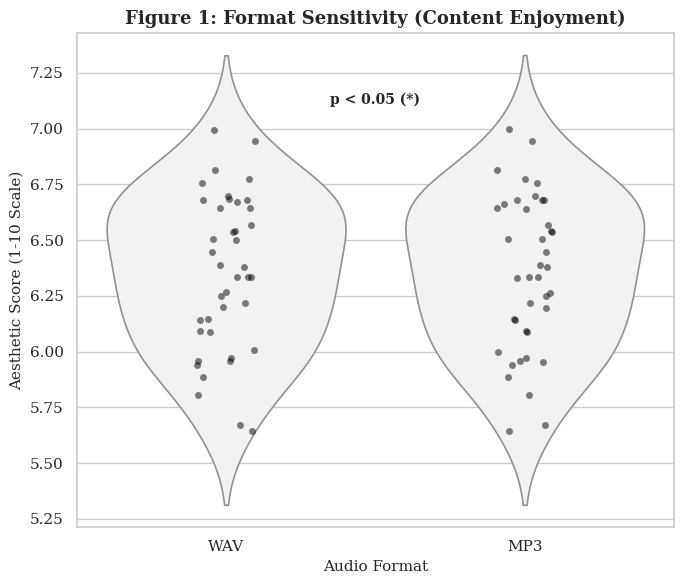

In [13]:
def execute_format_sensitivity_check(df: pd.DataFrame):
    """
    Performs Paired T-Tests on Audiobox AES metrics to test for any
    deviations caused by audio format (WAV vs. MP3).
    """
    print("--- Statistical Results: The Format Sensitivity Check ---")

    metrics = ['PC', 'PQ', 'CE', 'CU']
    metric_labels = {
        'PC': 'Production Complexity',
        'PQ': 'Production Quality',
        'CE': 'Content Enjoyment',
        'CU': 'Content Usefulness'
    }

    # Identify the metric with significant format deviation
    lead_metric = None
    min_p_value = 1.0

    for m in metrics:
        wav, mp3 = f'{m}_WAV', f'{m}_MP3'
        if wav in df.columns and mp3 in df.columns:
            data = df[[wav, mp3]].dropna()
            n = len(data)
            if n > 1:
                t_stat, p_val = ttest_rel(data[wav], data[mp3])
                mean_diff = (data[wav] - data[mp3]).mean()
                sig_marker = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

                print(f"{metric_labels[m]:<25}: Mean Diff = {mean_diff:+.5f} | t({n-1}) = {t_stat:+.2f} | p = {p_val:.4f} ({sig_marker})")

                # Track the finding for subsequent visualization
                if p_val < min_p_value:
                    min_p_value = p_val
                    lead_metric = m

    # Visualization: Only proceed if a significant format effect (p < 0.05) is discovered
    if lead_metric and min_p_value < 0.05:
        m = lead_metric
        print(f"\n--- Analysis Reveal ---")
        print(f"The '{metric_labels[m]}' metric is identified as the primary indicator of format sensitivity.")

        wav, mp3 = f'{m}_WAV', f'{m}_MP3'
        plt.figure(figsize=(7, 6))

        # Melt data for standard academic plotting format
        plot_data = df[[wav, mp3]].dropna().melt(var_name='Format', value_name='Score')
        plot_data['Format'] = plot_data['Format'].map({wav: 'WAV', mp3: 'MP3'})

        # Render distribution (Violin) and individual observations (Strip)
        sns.violinplot(x='Format', y='Score', data=plot_data, inner=None, color=".95", linewidth=1.2)
        sns.stripplot(x='Format', y='Score', data=plot_data, alpha=0.5, color="black", jitter=True)

        plt.title(f"Figure 1: Format Sensitivity ({metric_labels[m]})", fontsize=13, fontweight='bold')
        plt.ylabel("Aesthetic Score (1-10 Scale)", fontsize=11)
        plt.xlabel("Audio Format", fontsize=11)

        # Annotate with the discovered p-value - add small padding to max score to avoid overlapping
        sig_label = "p < 0.001 (***)" if min_p_value < 0.001 else "p < 0.01 (**)" if min_p_value < 0.01 else "p < 0.05 (*)"
        y_pos = df[wav].max() + 0.1
        plt.text(0.5, y_pos, sig_label, ha='center', va='bottom', fontsize=10, fontweight='bold')

        plt.tight_layout()
        plt.show()
    else:
        print("\nObservation: No statistically significant format-based deviations were detected.")

# --- Execution ---
if 'final_analysis_df' in locals():
    execute_format_sensitivity_check(final_analysis_df)
else:
    print("Error: Required dataframe 'final_analysis_df' is not present in the namespace.")

### Format-sensitivity check: threshold for the four simultaneous tests

While the previous cell performs the primary evaluation and identifies format sensitivities, the following block explicitly re-prints the raw p-values directly alongside the Bonferroni threshold for comprehensive transparency (Section 4.1).

In [14]:
# --- Bonferroni threshold for the four simultaneous format tests ------------
print("--- Format sensitivity: raw p-values and Bonferroni threshold ---")
for _m in ["PC", "PQ", "CE", "CU"]:
    _wav, _mp3 = f"{_m}_WAV", f"{_m}_MP3"
    if _wav in final_analysis_df.columns and _mp3 in final_analysis_df.columns:
        _d = final_analysis_df[[_wav, _mp3]].dropna()
        _t, _p = ttest_rel(_d[_wav], _d[_mp3])
        print(f"  {_m}: mean diff = {(_d[_wav] - _d[_mp3]).mean():+.5f} | "
              f"t({len(_d) - 1}) = {_t:+.2f} | p = {_p:.4f}")
print(f"  Bonferroni threshold for 4 simultaneous tests: alpha = {0.05 / 4:.4f}")


--- Format sensitivity: raw p-values and Bonferroni threshold ---
  PC: mean diff = +0.00042 | t(39) = +1.47 | p = 0.1487
  PQ: mean diff = +0.00047 | t(39) = +1.51 | p = 0.1394
  CE: mean diff = +0.00081 | t(39) = +2.37 | p = 0.0229
  CU: mean diff = +0.00023 | t(39) = +1.46 | p = 0.1526
  Bonferroni threshold for 4 simultaneous tests: alpha = 0.0125


## Comparative Analysis of Human Perceived Complexity and AES Scores

 Analysis of the relationship between the human **Perceived Complexity** scores from the LDP dataset and the Audiobox inferred **Production Complexity** scores.

 Spearman’s Rank Correlation and scatter plot with a LOWESS (Locally Weighted Scatterplot Smoothing) regression curve. Non-parametric approach to allow observing the trend without assuming a linear relationship. Analysis performed only on WAV files.

--- Human vs. Audiobox Model Complexity Scores (WAV) ---
Spearman's Rank Correlation: rho = +0.287
Observed Significance: p = 0.072 (ns)
Sample Size: N = 40


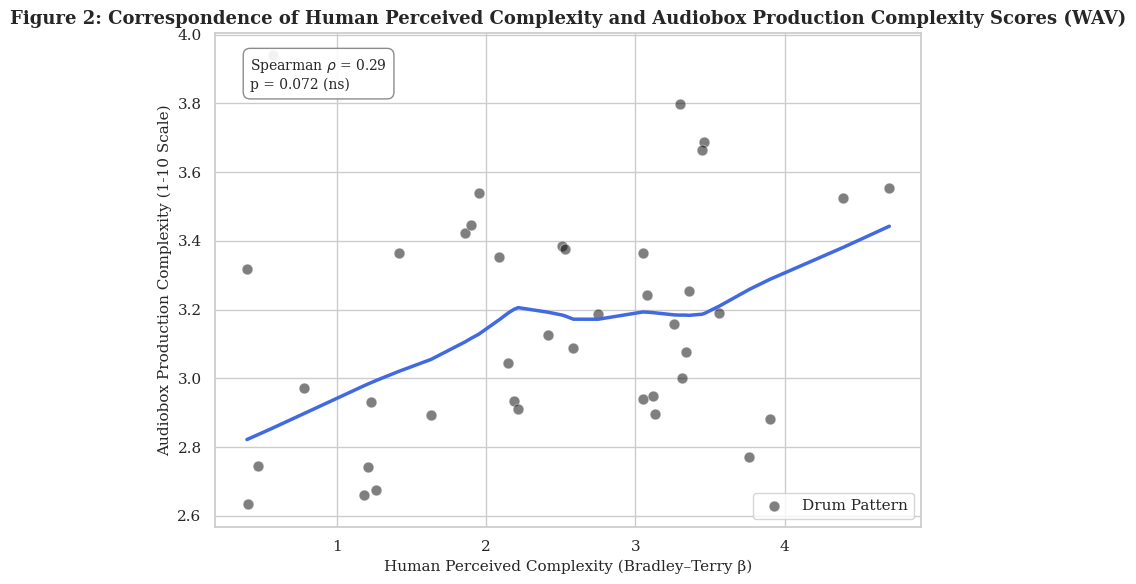

In [15]:
def analyze_complexity_correspondence(df: pd.DataFrame):
    """
    Investigates the relationship between human Perceived Complexity
    and Audiobox Production Complexity using WAV data.
    """
    print("--- Human vs. Audiobox Model Complexity Scores (WAV) ---")

    human_metric = 'PerceivedComplexity'
    machine_metric = 'PC_WAV'

    if human_metric in df.columns and machine_metric in df.columns:
        # Pairwise isolation to maximize data points (N=40)
        data = df[[human_metric, machine_metric]].dropna()
        n = len(data)

        if n > 2:
            rho, p_val = spearmanr(data[human_metric], data[machine_metric])
            sig_marker = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

            print(f"Spearman's Rank Correlation: rho = {rho:+.3f}")
            print(f"Observed Significance: p = {p_val:.3f} ({sig_marker})")
            print(f"Sample Size: N = {n}")

            plt.figure(figsize=(8, 6))

            # Scatter plot of individual observations
            sns.scatterplot(
                x=human_metric, y=machine_metric, data=data,
                color="black", alpha=0.5, s=60, label="Drum Pattern"
            )

            # LOWESS Regression to visualize the localized trend
            sns.regplot(
                x=human_metric, y=machine_metric, data=data,
                scatter=False, lowess=True, color="royalblue",
                line_kws={"linewidth": 2.5, "label": "LOWESS Trend Line"}
            )

            plt.title("Figure 2: Correspondence of Human Perceived Complexity and Audiobox Production Complexity Scores (WAV)", fontsize=13, fontweight='bold')
            plt.xlabel("Human Perceived Complexity (Bradley–Terry β)", fontsize=11)
            plt.ylabel("Audiobox Production Complexity (1-10 Scale)", fontsize=11)

            # Annotation of results
            stat_text = f"Spearman $\\rho$ = {rho:.2f}\np = {p_val:.3f} ({sig_marker})"
            plt.text(
                0.05, 0.95, stat_text, transform=plt.gca().transAxes,
                verticalalignment='top', fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.9)
            )

            plt.legend(loc='lower right')
            plt.tight_layout()
            plt.show()

        else:
            print("Error: Dataset size insufficient for meaningful correlation.")
    else:
        print(f"Error: Required variables ({human_metric} or {machine_metric}) are absent.")

# --- Execution ---
if 'final_analysis_df' in locals():
    analyze_complexity_correspondence(final_analysis_df)
else:
    print("Error: 'final_analysis_df' is not available.")

##  Analysis of Acoustic Determinants of AES Scoring

 Check which features of the drum patterns may be important for the Audiobox model’s metrics compared to the human Perceived Complexity benchmark.

 Spearman’s Rank Correlation Matrix **Perceived Complexity** and the four **Audiobox AES metrics** (WAV) against **16 features** from stimuli metadata set. These include rhythmic density (Onsets), syncopation indices, mathematical complexity (Kolmogorov), and temporal drift. Pairwise deletion is employed to ensure maximum sample utilization for each correlation pair.


All correlations executed with full sample size (N=40).

Saved high-definition correlation matrix to: CorrelationMatrix.tiff


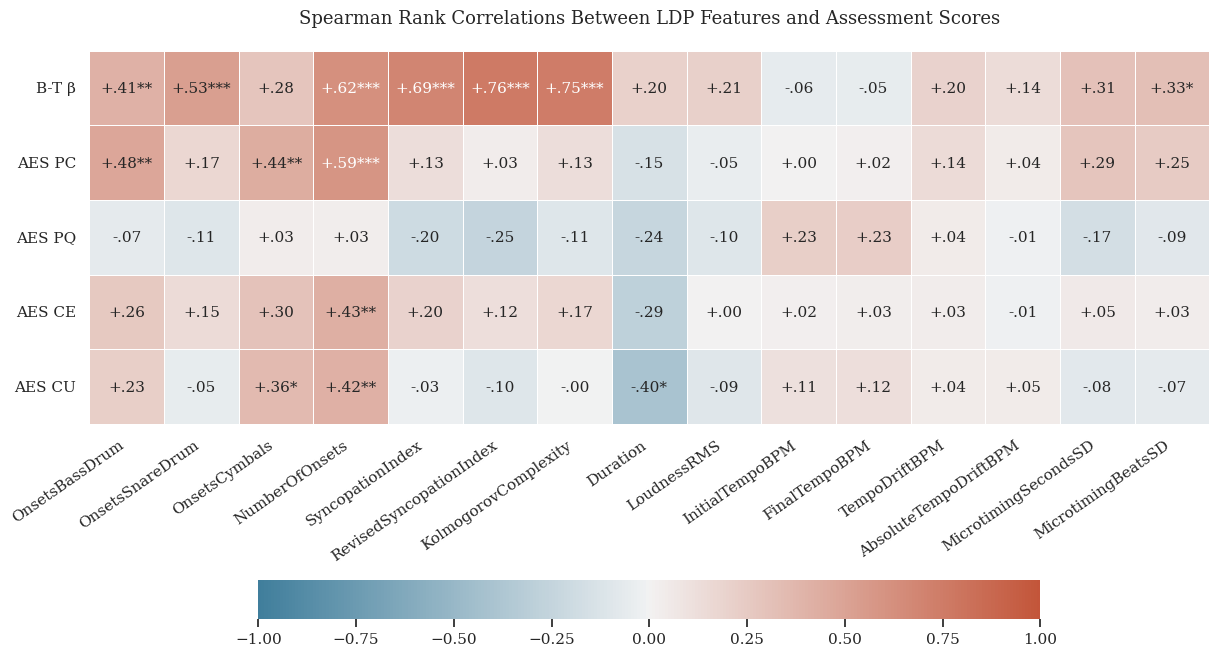

In [16]:
def grand_correlation_analysis(df: pd.DataFrame, tiff_filename='CorrelationMatrix.tiff'):
    """
    Generates a correlation matrix to identify musicological features
    influencing human perception and Audiobox model evaluations,
    including a transparency report for sample sizes.
    """
    #print("--- Statistical Results: Evaluation of Acoustic Determinants ---")

    target_vars = ['PerceivedComplexity', 'PC_WAV', 'PQ_WAV', 'CE_WAV', 'CU_WAV']
    target_labels = {
        'PerceivedComplexity': 'B-T β',
        'PC_WAV': 'AES PC',
        'PQ_WAV': 'AES PQ',
        'CE_WAV': 'AES CE',
        'CU_WAV': 'AES CU'
    }

    feature_vars = [
        'OnsetsBassDrum', 'OnsetsSnareDrum', 'OnsetsCymbals', 'NumberOfOnsets',
        'SyncopationIndex', 'RevisedSyncopationIndex', 'KolmogorovComplexity',
        'Duration', 'LoudnessRMS', 'InitialTempoBPM', 'FinalTempoBPM',
        'TempoDriftBPM', 'AbsoluteTempoDriftBPM',
        'MicrotimingSecondsSD', 'MicrotimingBeatsSD'
    ]

    avail_targets = [t for t in target_vars if t in df.columns]
    avail_features = [f for f in feature_vars if f in df.columns]

    corr_matrix = pd.DataFrame(index=[target_labels[t] for t in avail_targets], columns=avail_features, dtype=float)
    annot_matrix = pd.DataFrame(index=[target_labels[t] for t in avail_targets], columns=avail_features, dtype=str)

    # Transparency report storage
    exclusion_report = []

    for target in avail_targets:
        target_label = target_labels[target]
        for feature in avail_features:
            pair_df = df[[feature, target]].dropna().copy()

            n_current = len(pair_df)

            # Log any sample size that falls below the full cohort of 40
            if n_current < 40:
                exclusion_report.append(f"Pair ({target_label} + {feature}): N = {n_current}")

            if n_current > 5:
                rho, p_val = spearmanr(pair_df[feature], pair_df[target])
                corr_matrix.loc[target_label, feature] = rho
                stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else ""
                annot_matrix.loc[target_label, feature] = f"{rho:+.2f}".replace("+0.", "+.").replace("-0.", "-.") + stars

    # --- Print Transparency Report ---
    if exclusion_report:
        print("\n[Transparency Report: Sample Size Deviations]")
        # Using set() to avoid redundant reporting for the same feature anomalies
        for entry in sorted(list(set(exclusion_report))):
            print(f" - {entry}")
    else:
        print("\nAll correlations executed with full sample size (N=40).")

    # --- Visualization ---
    plt.figure(figsize=(16, 7))
    sns.set_theme(style="white", font="serif")
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    sns.heatmap(
        corr_matrix.astype(float), cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
        square=True, linewidths=.5, cbar_kws={"orientation": "horizontal", "shrink": .5, "pad": 0.25},
        annot=annot_matrix.values, fmt="", annot_kws={"size": 11}
    )

    plt.title("Spearman Rank Correlations Between LDP Features and Assessment Scores", fontsize=13, pad=20)
    plt.xlabel("")
    plt.ylabel("")

    plt.xticks(rotation=35, ha='right', fontsize=11)
    plt.yticks(rotation=0, fontsize=11)

    plt.tight_layout()

    if tiff_filename:
        plt.savefig(tiff_filename, format='tiff', dpi=600, bbox_inches='tight', pil_kwargs={"compression": "tiff_lzw"})
        print(f"\nSaved high-definition correlation matrix to: {tiff_filename}")

    plt.show()

# --- Execution ---
if 'final_analysis_df' in locals():
    grand_correlation_analysis(final_analysis_df)
else:
    print("Error: 'final_analysis_df' is not defined.")

Human Perceived Complexity (N=40): OOB R² = 0.590 | Repeated 5-Fold CV R² = 0.476 ± 0.420
Audiobox Production Complexity (N=40): OOB R² = 0.291 | Repeated 5-Fold CV R² = 0.181 ± 0.397


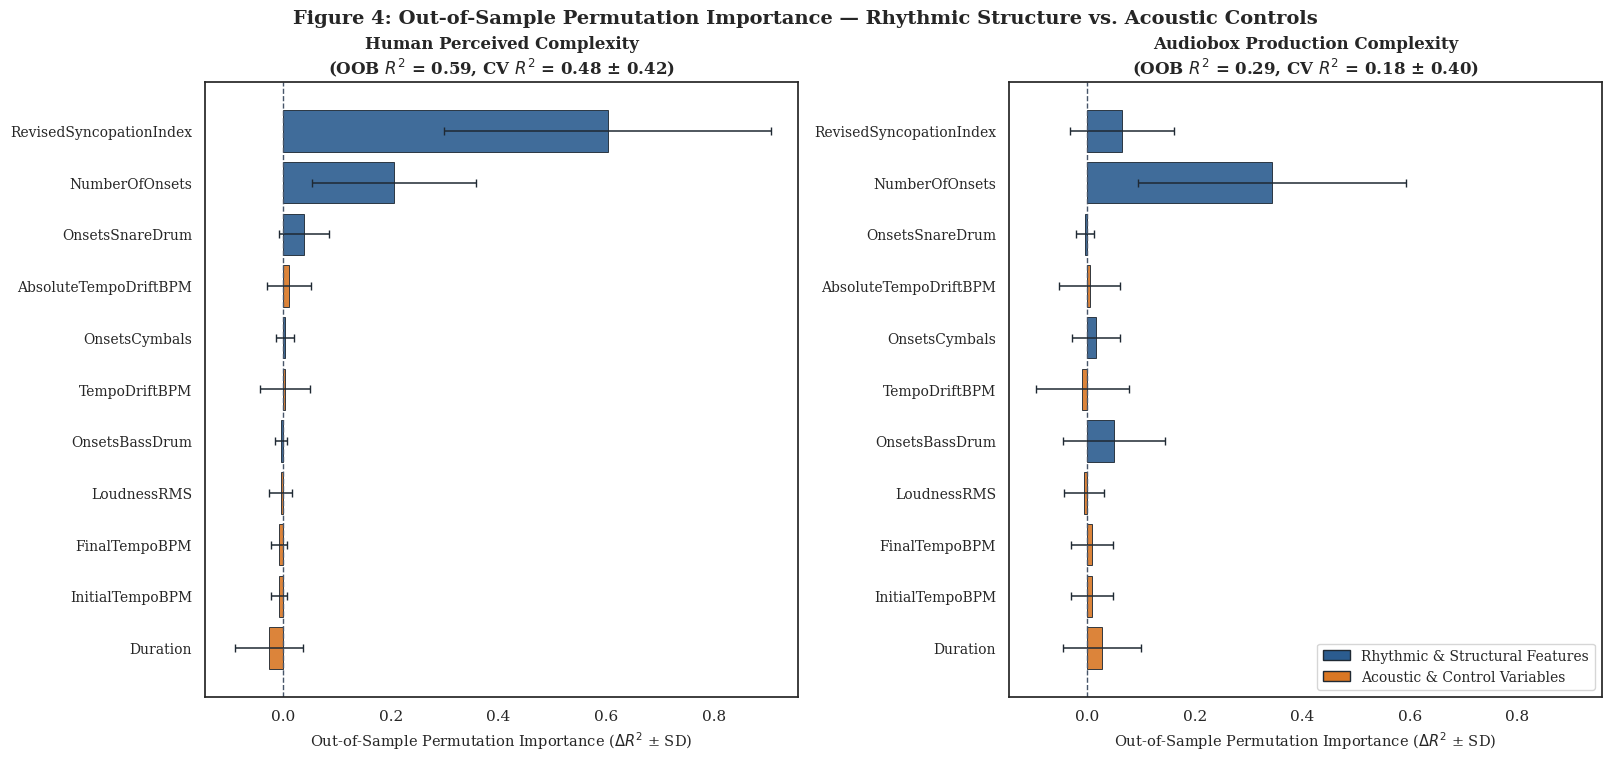

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score
from matplotlib.patches import Patch
import logging

logger = logging.getLogger("AES_Preprint_Analysis")


def analyze_grouped_permutation_importance(
    df: pd.DataFrame,
    n_estimators: int = 200,
    n_splits: int = 5,
    n_repeats: int = 20,
    perm_repeats: int = 10,
    random_state: int = 42,
):
    """
    Evaluates out-of-sample Permutation Importance via Repeated K-Fold CV,
    explicitly separating rhythmic/structural measures from acoustic control variables.
    """
    logger.info("Executing Repeated K-Fold Permutation Importance analysis...")

    targets = {
        "Human Perceived Complexity": "PerceivedComplexity",
        "Audiobox Production Complexity": "PC_WAV",
    }

    feature_groups = {
        "Rhythmic & Structural": [
            "OnsetsBassDrum",
            "OnsetsSnareDrum",
            "OnsetsCymbals",
            "NumberOfOnsets",
            "RevisedSyncopationIndex",
        ],
        "Acoustic & Control": [
            "Duration",
            "LoudnessRMS",
            "InitialTempoBPM",
            "FinalTempoBPM",
            "TempoDriftBPM",
            "AbsoluteTempoDriftBPM",
        ],
    }

    # Build ordered feature list and category lookup
    feature_to_group = {}
    ordered_candidates = []
    for group_name, cols in feature_groups.items():
        for col in cols:
            if col in df.columns:
                feature_to_group[col] = group_name
                ordered_candidates.append(col)

    if not ordered_candidates:
        raise ValueError("None of the specified predictor features were found in DataFrame.")

    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    results_summary = {}

    for label, target in targets.items():
        if target not in df.columns:
            raise KeyError(f"Target column '{target}' is missing from DataFrame.")

        model_df = df[ordered_candidates + [target]].dropna().copy()
        X = model_df[ordered_candidates]
        y = model_df[target]

        # Full-sample OOB diagnostic fit (diagnostic only, not used for importance ranking)
        rf_oob = RandomForestRegressor(
            n_estimators=n_estimators,
            oob_score=True,
            random_state=random_state,
            n_jobs=-1,
        )
        rf_oob.fit(X, y)

        cv_r2_scores = []
        fold_importances = []

        for split_idx, (train_idx, test_idx) in enumerate(rkf.split(X)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            rf = RandomForestRegressor(
                n_estimators=n_estimators,
                random_state=random_state + split_idx,
                n_jobs=-1,
            )
            rf.fit(X_train, y_train)

            y_pred = rf.predict(X_test)
            cv_r2_scores.append(r2_score(y_test, y_pred))

            perm_res = permutation_importance(
                rf,
                X_test,
                y_test,
                n_repeats=perm_repeats,
                random_state=random_state + split_idx,
                scoring="r2",
                n_jobs=-1,
            )
            fold_importances.append(perm_res.importances_mean)

        imp_matrix = np.vstack(fold_importances)
        summary_df = pd.DataFrame({
            "Feature": ordered_candidates,
            "Group": [feature_to_group[f] for f in ordered_candidates],
            "Importance_Mean": imp_matrix.mean(axis=0),
            "Importance_SD": imp_matrix.std(axis=0, ddof=1),
        })

        results_summary[label] = {
            "df": summary_df,
            "oob_r2": float(rf_oob.oob_score_),
            "cv_r2_mean": float(np.mean(cv_r2_scores)),
            "cv_r2_sd": float(np.std(cv_r2_scores, ddof=1)),
            "n": len(model_df),
        }

        print(
            f"{label} (N={len(model_df)}): "
            f"OOB R² = {rf_oob.oob_score_:.3f} | "
            f"Repeated 5-Fold CV R² = {np.mean(cv_r2_scores):.3f} ± {np.std(cv_r2_scores, ddof=1):.3f}"
        )

    # Order features by Human Perceived Complexity permutation importance
    human_df = results_summary["Human Perceived Complexity"]["df"]
    master_order = (
        human_df.sort_values("Importance_Mean", ascending=False)["Feature"].tolist()
    )

    group_palette = {
        "Rhythmic & Structural": "#2b5c8f",
        "Acoustic & Control": "#d97724",
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharex=True, constrained_layout=True)
    sns.set_theme(style="whitegrid", font="serif")

    for idx, label in enumerate(targets.keys()):
        ax = axes[idx]
        res = results_summary[label]
        plot_df = res["df"].set_index("Feature").reindex(master_order).reset_index()

        bar_colors = [group_palette[g] for g in plot_df["Group"]]
        y_positions = np.arange(len(plot_df))

        ax.barh(
            y_positions,
            plot_df["Importance_Mean"],
            xerr=plot_df["Importance_SD"],
            color=bar_colors,
            edgecolor="#1f2933",
            linewidth=0.7,
            alpha=0.9,
            error_kw={"ecolor": "#1f2933", "elinewidth": 1.1, "capsize": 3},
        )
        ax.axvline(0.0, color="#475569", linestyle="--", linewidth=1.0)
        ax.set_yticks(y_positions)
        ax.set_yticklabels(plot_df["Feature"], fontsize=10)
        ax.invert_yaxis()

        subtitle = (
            f"{label}\n"
            f"(OOB $R^2$ = {res['oob_r2']:.2f}, CV $R^2$ = {res['cv_r2_mean']:.2f} ± {res['cv_r2_sd']:.2f})"
        )
        ax.set_title(subtitle, fontsize=12, fontweight="bold")
        ax.set_xlabel("Out-of-Sample Permutation Importance ($\\Delta R^2$ ± SD)", fontsize=10.5)

    legend_handles = [
        Patch(facecolor=group_palette["Rhythmic & Structural"], edgecolor="#1f2933", label="Rhythmic & Structural Features"),
        Patch(facecolor=group_palette["Acoustic & Control"], edgecolor="#1f2933", label="Acoustic & Control Variables"),
    ]
    axes[1].legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=10)

    fig.suptitle(
        "Figure 4: Out-of-Sample Permutation Importance — Rhythmic Structure vs. Acoustic Controls",
        fontsize=14,
        fontweight="bold",
    )
    plt.show()
    return results_summary


# --- Execution ---
if "final_analysis_df" in locals() and not final_analysis_df.empty:
    perm_importance_results = analyze_grouped_permutation_importance(final_analysis_df)
else:
    print("Error: 'final_analysis_df' is not defined or empty.")

Spearman rank correlation between the human Bradley–Terry complexity score and the
Audiobox Production Complexity score, computed for the WAV and the MP3 renditions,
with a Fisher-z confidence interval and the minimum detectable effect at this
sample size (Sections 4.1, 4.2 and 5.1 of the paper).


In [18]:
def report_correspondence(df, target, label, alpha=0.05):
    """Spearman rho with Fisher-z CI and minimum detectable effect."""
    data = df[["PerceivedComplexity", target]].dropna()
    n = len(data)
    rho, p = spearmanr(data["PerceivedComplexity"], data[target])
    z = np.arctanh(rho)
    se = 1.0 / np.sqrt(n - 3)
    zc = norm.ppf(1 - alpha / 2)
    lo, hi = np.tanh(z - zc * se), np.tanh(z + zc * se)
    mde = {int(pw * 100): np.tanh((zc + norm.ppf(pw)) / np.sqrt(n - 3))
           for pw in (0.80, 0.90)}
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    print(f"{label}: rho = {rho:+.3f}, p = {p:.3f} ({sig}), N = {n}")
    print(f"    95% CI (Fisher z) = [{lo:+.2f}, {hi:+.2f}] | rho^2 = {rho ** 2:.3f}")
    print("    minimum detectable |rho|: " +
          ", ".join(f"{k}% power -> {v:.2f}" for k, v in mde.items()))
    return rho, p


if "final_analysis_df" in globals():
    print("--- Human Perceived Complexity vs. Audiobox Production Complexity ---")
    report_correspondence(final_analysis_df, "PC_WAV", "WAV rendition")
    report_correspondence(final_analysis_df, "PC_MP3", "MP3 rendition")
else:
    print("Error: 'final_analysis_df' is not defined.")


--- Human Perceived Complexity vs. Audiobox Production Complexity ---
WAV rendition: rho = +0.287, p = 0.072 (ns), N = 40
    95% CI (Fisher z) = [-0.03, +0.55] | rho^2 = 0.083
    minimum detectable |rho|: 80% power -> 0.43, 90% power -> 0.49
MP3 rendition: rho = +0.285, p = 0.075 (ns), N = 40
    95% CI (Fisher z) = [-0.03, +0.55] | rho^2 = 0.081
    minimum detectable |rho|: 80% power -> 0.43, 90% power -> 0.49


### Significant correlations (Table 3) and the same selection on the MP3 branch

Prints the rows of Table 3 — the correlations with |ρ| ≥ .30 and p < .05 — and the
identical selection computed on the MP3 renditions, which shows that the pattern
of results does not depend on the rendition format.


In [19]:
# --- Table 3: significant Spearman correlations, WAV and MP3 branches ------
FEATURES_16 = [
    "OnsetsBassDrum", "OnsetsSnareDrum", "OnsetsCymbals", "NumberOfOnsets",
    "SyncopationIndex", "RevisedSyncopationIndex", "KolmogorovComplexity",
    "Duration", "LoudnessRMS", "InitialTempoBPM", "FinalTempoBPM",
    "TempoDriftBPM", "AbsoluteTempoDriftBPM", "MicrotimingSecondsSD",
    "MicrotimingBeatsSD", "Year",
]
TARGETS_WAV = ["PerceivedComplexity", "PC_WAV", "PQ_WAV", "CE_WAV", "CU_WAV"]
TARGETS_MP3 = ["PC_MP3", "PQ_MP3", "CE_MP3", "CU_MP3"]


def significance_table(df, target_vars, feature_vars, threshold=0.30, alpha=0.05):
    """Rows with |rho| >= threshold and p < alpha, with significance markers."""
    rows = []
    for target in target_vars:
        for feature in feature_vars:
            pair = df[[feature, target]].dropna()
            if feature == "Year":
                pair = pair[pair[feature] > 0]
            if len(pair) < 5:
                continue
            rho, p = spearmanr(pair[feature], pair[target])
            if abs(rho) >= threshold and p < alpha:
                stars = "***" if p < 0.001 else "**" if p < 0.01 else "*"
                rows.append({"Metric": target, "Feature": feature,
                             "rho": f"{rho:+.2f}", "p": f"{p:.4f}", "Sig.": stars})
    return pd.DataFrame(rows)


if "final_analysis_df" in globals():
    print("--- Table 3 (WAV branch) ---")
    print(significance_table(final_analysis_df, TARGETS_WAV, FEATURES_16).to_string(index=False))
    print("\n--- same selection on the MP3 branch (robustness to the rendition format) ---")
    print(significance_table(final_analysis_df, TARGETS_MP3, FEATURES_16).to_string(index=False))
else:
    print("Error: 'final_analysis_df' is not defined.")


--- Table 3 (WAV branch) ---
             Metric                 Feature   rho      p Sig.
PerceivedComplexity          OnsetsBassDrum +0.41 0.0080   **
PerceivedComplexity         OnsetsSnareDrum +0.53 0.0005  ***
PerceivedComplexity          NumberOfOnsets +0.62 0.0000  ***
PerceivedComplexity        SyncopationIndex +0.69 0.0000  ***
PerceivedComplexity RevisedSyncopationIndex +0.76 0.0000  ***
PerceivedComplexity    KolmogorovComplexity +0.75 0.0000  ***
PerceivedComplexity      MicrotimingBeatsSD +0.33 0.0399    *
             PC_WAV          OnsetsBassDrum +0.48 0.0019   **
             PC_WAV           OnsetsCymbals +0.44 0.0043   **
             PC_WAV          NumberOfOnsets +0.59 0.0001  ***
             CE_WAV          NumberOfOnsets +0.43 0.0058   **
             CU_WAV           OnsetsCymbals +0.36 0.0235    *
             CU_WAV          NumberOfOnsets +0.42 0.0071   **
             CU_WAV                Duration -0.40 0.0106    *

--- same selection on the MP3 branch (ro

## Comparative Feature Importance: Rhythmic Structure vs. Acoustic Controls

To evaluate which stimulus properties drive human **Perceived Complexity** versus Audiobox **Production Complexity (`PC_WAV`)**, predictors are explicitly partitioned into two theoretical groups:
1. **Rhythmic & Structural Features**: `OnsetsBassDrum`, `OnsetsSnareDrum`, `OnsetsCymbals`, `NumberOfOnsets`, and `RevisedSyncopationIndex`.
2. **Acoustic & Control Variables**: `Duration`, `LoudnessRMS`, `InitialTempoBPM`, `FinalTempoBPM`, `TempoDriftBPM`, and `AbsoluteTempoDriftBPM`.

Because standard impurity-based importance (MDI) in small samples ($N = 40$) can be biased toward continuous variables with high cardinality and does not reflect out-of-sample generalization, we estimate **out-of-sample Permutation Importance** across **Repeated 5-Fold Cross-Validation** (`5 folds × 20 repeats = 100 splits`) alongside out-of-bag ($R^2_{\text{OOB}}$) and cross-validated ($R^2_{\text{CV}}$) explanatory power.

Wyniki obliczeń Random Forest są już w pamięci. Przechodzę prosto do rysowania...

Saved high-definition feature importance figure to: FeatureImportance_RandomForest.tiff


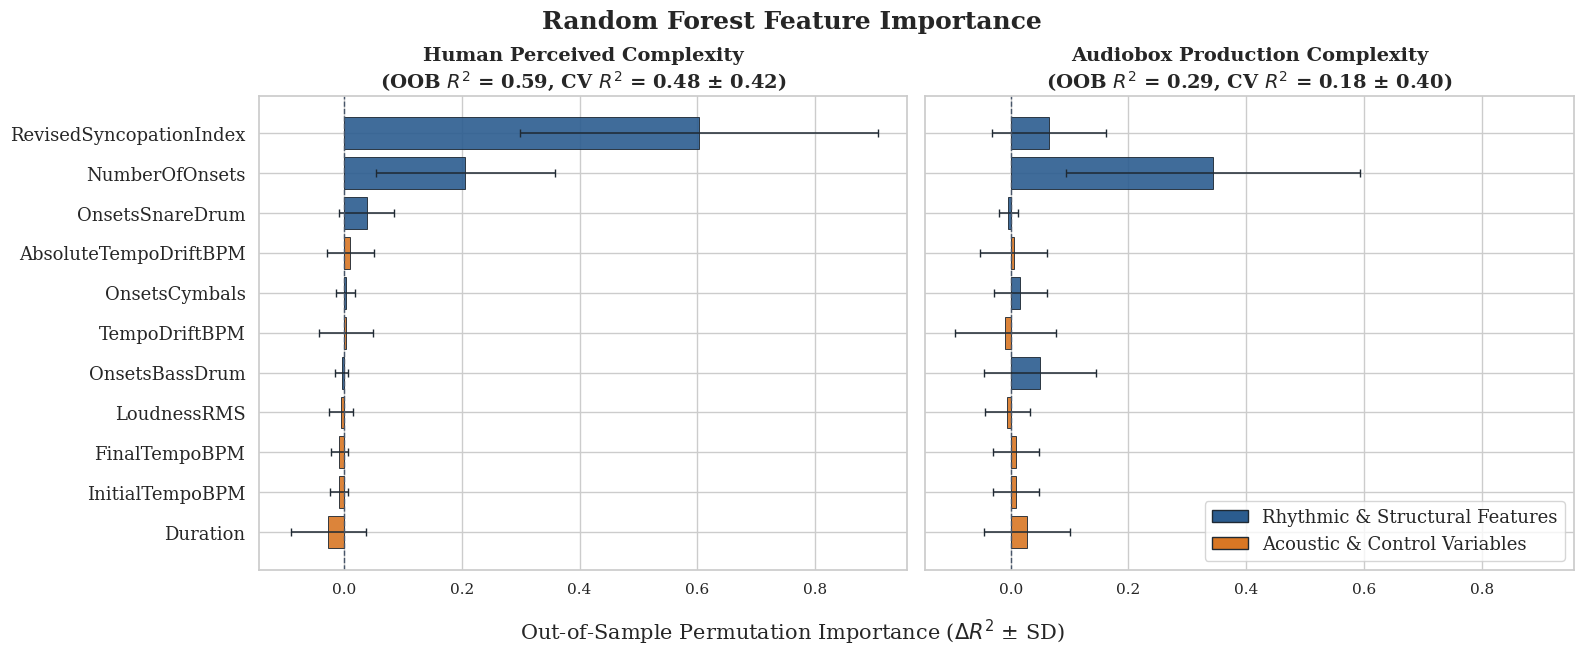

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import logging

logger = logging.getLogger("AES_Preprint_Analysis")


def compute_permutation_importance(
    df: pd.DataFrame,
    n_estimators: int = 200,
    n_splits: int = 5,
    n_repeats: int = 20,
    perm_repeats: int = 10,
    random_state: int = 42,
):
    """
    Evaluates out-of-sample Permutation Importance via Repeated K-Fold CV.
    Separates the heavy computation from the plotting logic.
    """
    logger.info("Executing Repeated K-Fold Permutation Importance analysis...")

    targets = {
        "Human Perceived Complexity": "PerceivedComplexity",
        "Audiobox Production Complexity": "PC_WAV",
    }

    feature_groups = {
        "Rhythmic & Structural": [
            "OnsetsBassDrum",
            "OnsetsSnareDrum",
            "OnsetsCymbals",
            "NumberOfOnsets",
            "RevisedSyncopationIndex",
        ],
        "Acoustic & Control": [
            "Duration",
            "LoudnessRMS",
            "InitialTempoBPM",
            "FinalTempoBPM",
            "TempoDriftBPM",
            "AbsoluteTempoDriftBPM",
        ],
    }

    feature_to_group = {}
    ordered_candidates = []
    for group_name, cols in feature_groups.items():
        for col in cols:
            if col in df.columns:
                feature_to_group[col] = group_name
                ordered_candidates.append(col)

    if not ordered_candidates:
        raise ValueError("None of the specified predictor features were found in DataFrame.")

    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    results_summary = {}

    for label, target in targets.items():
        if target not in df.columns:
            raise KeyError(f"Target column '{target}' is missing from DataFrame.")

        model_df = df[ordered_candidates + [target]].dropna().copy()
        X = model_df[ordered_candidates]
        y = model_df[target]

        rf_oob = RandomForestRegressor(
            n_estimators=n_estimators,
            oob_score=True,
            random_state=random_state,
            n_jobs=-1,
        )
        rf_oob.fit(X, y)

        cv_r2_scores = []
        fold_importances = []

        for split_idx, (train_idx, test_idx) in enumerate(rkf.split(X)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            rf = RandomForestRegressor(
                n_estimators=n_estimators,
                random_state=random_state + split_idx,
                n_jobs=-1,
            )
            rf.fit(X_train, y_train)

            y_pred = rf.predict(X_test)
            cv_r2_scores.append(r2_score(y_test, y_pred))

            perm_res = permutation_importance(
                rf,
                X_test,
                y_test,
                n_repeats=perm_repeats,
                random_state=random_state + split_idx,
                scoring="r2",
                n_jobs=-1,
            )
            fold_importances.append(perm_res.importances_mean)

        imp_matrix = np.vstack(fold_importances)
        summary_df = pd.DataFrame({
            "Feature": ordered_candidates,
            "Group": [feature_to_group[f] for f in ordered_candidates],
            "Importance_Mean": imp_matrix.mean(axis=0),
            "Importance_SD": imp_matrix.std(axis=0, ddof=1),
        })

        results_summary[label] = {
            "df": summary_df,
            "oob_r2": float(rf_oob.oob_score_),
            "cv_r2_mean": float(np.mean(cv_r2_scores)),
            "cv_r2_sd": float(np.std(cv_r2_scores, ddof=1)),
            "n": len(model_df),
        }

        print(
            f"{label} (N={len(model_df)}): "
            f"OOB R² = {rf_oob.oob_score_:.3f} | "
            f"Repeated 5-Fold CV R² = {np.mean(cv_r2_scores):.3f} ± {np.std(cv_r2_scores, ddof=1):.3f}"
        )

    return results_summary


def plot_permutation_importance(results_summary, tiff_filename="FeatureImportance_RandomForest.tiff"):
    """
    Renders the plotting logic using pre-computed permutation importance results.
    Optimized for Word document insertion (larger fonts, shared labels, adjusted spacing).
    """
    targets = list(results_summary.keys())
    human_df = results_summary[targets[0]]["df"]
    master_order = human_df.sort_values("Importance_Mean", ascending=False)["Feature"].tolist()

    group_palette = {
        "Rhythmic & Structural": "#2b5c8f",
        "Acoustic & Control": "#d97724",
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharex=True)
    sns.set_theme(style="whitegrid", font="serif")

    for idx, label in enumerate(targets):
        ax = axes[idx]
        res = results_summary[label]
        plot_df = res["df"].set_index("Feature").reindex(master_order).reset_index()

        bar_colors = [group_palette[g] for g in plot_df["Group"]]
        y_positions = np.arange(len(plot_df))

        ax.barh(
            y_positions,
            plot_df["Importance_Mean"],
            xerr=plot_df["Importance_SD"],
            color=bar_colors,
            edgecolor="#1f2933",
            linewidth=0.7,
            alpha=0.9,
            error_kw={"ecolor": "#1f2933", "elinewidth": 1.1, "capsize": 3},
        )
        ax.axvline(0.0, color="#475569", linestyle="--", linewidth=1.0)
        ax.set_yticks(y_positions)

        # Conditionally remove Y-axis labels for the second plot
        if idx == 0:
            ax.set_yticklabels(plot_df["Feature"], fontsize=13)
        else:
            ax.set_yticklabels([])

        ax.invert_yaxis()
        ax.tick_params(axis='x', labelsize=11)

        subtitle = (
            f"{label}\n"
            f"(OOB $R^2$ = {res['oob_r2']:.2f}, CV $R^2$ = {res['cv_r2_mean']:.2f} ± {res['cv_r2_sd']:.2f})"
        )
        ax.set_title(subtitle, fontsize=14, fontweight="bold")
        ax.set_xlabel("")

    legend_handles = [
        Patch(facecolor=group_palette["Rhythmic & Structural"], edgecolor="#1f2933", label="Rhythmic & Structural Features"),
        Patch(facecolor=group_palette["Acoustic & Control"], edgecolor="#1f2933", label="Acoustic & Control Variables"),
    ]
    axes[1].legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=13)

    # Add a single, shared X-axis label with increased font size
    fig.supxlabel(r"Out-of-Sample Permutation Importance ($\Delta R^2$ ± SD)",
                  fontsize=15,
                  y=0.1)

    # Push the main title slightly higher with increased font size
    fig.suptitle(
        "Random Forest Feature Importance",
        x=0.5,
        y=0.95,
        ha="center",
        fontsize=18,
        fontweight="bold",
    )

    # Adjust layout manually to leave space for suptitle and supxlabel
    plt.tight_layout(rect=[0, 0.08, 1, 0.98])

    if tiff_filename:
        plt.savefig(tiff_filename, format='tiff', dpi=600, bbox_inches='tight', pil_kwargs={"compression": "tiff_lzw"})
        print(f"\nSaved high-definition feature importance figure to: {tiff_filename}")

    plt.show()


# --- Execution ---
# Smart execution: Skip the 5-minute compute if it is already in memory
if "perm_importance_results" not in locals():
    if "final_analysis_df" in locals() and not final_analysis_df.empty:
        print("Rozpoczynam obliczenia Random Forest (to może zająć kilka minut)...")
        perm_importance_results = compute_permutation_importance(final_analysis_df)
    else:
        print("Error: 'final_analysis_df' is not defined or empty.")
else:
    print("Wyniki obliczeń Random Forest są już w pamięci. Przechodzę prosto do rysowania...")

# Plot the results
if "perm_importance_results" in locals() and perm_importance_results is not None:
    plot_permutation_importance(perm_importance_results)


### Linear reference points: OLS on the 11 predictors and single-predictor models

The Random Forest results of Section 4.4 are complemented by an ordinary least
squares regression on the same 11 predictors and by single-predictor models for
the four objective complexity measures of Senn et al. (2023), using the same
repeated 5-fold cross-validation protocol (5 folds × 20 repeats, seed 42).


In [22]:
# --- OLS on the 11 predictors + single-predictor benchmarks ----------------
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score

PREDICTORS_11 = [
    "OnsetsBassDrum", "OnsetsSnareDrum", "OnsetsCymbals", "NumberOfOnsets",
    "RevisedSyncopationIndex", "Duration", "LoudnessRMS", "InitialTempoBPM",
    "FinalTempoBPM", "TempoDriftBPM", "AbsoluteTempoDriftBPM",
]


def cv_r2_linear(X, y, n_splits=5, n_repeats=20, random_state=42):
    """Repeated K-fold CV R^2 of an OLS fit (same protocol as the RF models)."""
    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    scores = []
    for train_idx, test_idx in rkf.split(X):
        model = LinearRegression().fit(X.iloc[train_idx], y.iloc[train_idx])
        scores.append(r2_score(y.iloc[test_idx], model.predict(X.iloc[test_idx])))
    return float(np.mean(scores)), float(np.std(scores, ddof=1))


if "final_analysis_df" in globals():
    _model_df = final_analysis_df[PREDICTORS_11 + ["PerceivedComplexity"]].dropna()
    _mean_r2, _sd_r2 = cv_r2_linear(_model_df[PREDICTORS_11], _model_df["PerceivedComplexity"])
    print(f"OLS on the 11 predictors: CV R2 = {_mean_r2:.2f} +- {_sd_r2:.2f}")
    for _feature in ["RevisedSyncopationIndex", "KolmogorovComplexity",
                     "SyncopationIndex", "NumberOfOnsets"]:
        _sub = final_analysis_df[[_feature, "PerceivedComplexity"]].dropna()
        _m, _s = cv_r2_linear(_sub[[_feature]], _sub["PerceivedComplexity"])
        print(f"  single predictor {_feature:<24}: CV R2 = {_m:.2f} +- {_s:.2f}")
else:
    print("Error: 'final_analysis_df' is not defined.")


OLS on the 11 predictors: CV R2 = 0.42 +- 0.38
  single predictor RevisedSyncopationIndex : CV R2 = 0.38 +- 0.39
  single predictor KolmogorovComplexity    : CV R2 = 0.37 +- 0.34
  single predictor SyncopationIndex        : CV R2 = 0.31 +- 0.33
  single predictor NumberOfOnsets          : CV R2 = 0.11 +- 0.51
